# Junior Data Analyst — Defect screening on component images

**How to run:** keep this notebook next to `train.csv`, `test.csv` and `images/`, then *Run All* (under a minute, CPU
only). Needs `numpy pandas scipy scikit-learn opencv-python matplotlib Pillow`. It writes `predictions.csv`. All
randomness is seeded (`SEED = 42`).

## The answer in short
**The question:** alerts went up. Is it the parts, the shooting conditions, or the data?

1. **The parts.** The real share of defective plates rose from **17%** on the first day to **48%** on 6 Nov (BATCH-C).
   Almost all of the increase is **edge chips and missing holes**, which are made in production, not by the camera.
2. **The data hid it.** About **1 in 11** inspector labels is wrong. Most are "stain" labels on clean plates, mostly on
   the first day, which made the first day look as bad as the later ones.
3. **Not the shooting conditions.** Camera B's exposure is unstable, but it does not change how many defects are found.

**Recommendation:** check what changed in production on 6 Nov, and give the inspectors a clear definition of "stain".

**Solution:** a simple rule flags a plate if any of four image measurements looks wrong (a missing hole, a chipped
edge, a line, a dark blob). On the validation set it caught 11 of the 17 labelled defects with no false alarms, and 4 of
the 6 it missed are wrong "stain" labels. `predictions.csv` holds its 72 test predictions.

**How sure:** the wrong labels are confirmed three independent ways (the image measurements, a visual review, and
the image statistics, where the false stains are indistinguishable from clean plates). The time findings rest on 4 days
of data, 42 images a day, so they are strong leads, not proof.

| Part | Content |
|---|---|
| A | the data: labels, defect rate per camera, one chart |
| B | sample images and two image measurements |
| C | the rule and `predictions.csv` |
| D | validation results and one error explained |
| R (optional) | the evidence behind the answer above |
| E | conclusions, limitations, how AI was used |

<details><summary><b>Plain-language glossary</b> (click to open)</summary>

- **95% interval (Wilson):** the range a rate could plausibly take, given how few images it is based on.
- **p-value (chi-square, Fisher, Kruskal-Wallis, permutation):** how surprising a difference would be if only chance
  were at work. Small (below about 0.05) means "probably not chance". With many comparisons a stricter bar is
  needed (**Bonferroni**: divide 0.05 by the number of comparisons).
- **AUC:** how well a measurement ranks defects above OK plates. 0.5 = a coin flip, 1.0 = perfect.
- **Out-of-fold:** each image is scored by a model that never saw it in training.
- **Otsu threshold:** an automatic dark/light cut-off computed separately for every image.
- **Convexity defect:** a dent in the outline of a shape (used to find chipped edges).
- **Top-hat / black-hat filter:** picks out thin bright / thin dark lines (used to find scratches).
</details>

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage, stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "test:", test.shape)
train.head()

train: (168, 10) test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


### Sanity checks before any analysis
The analysis below is only meaningful if these hold, so they are asserted rather than eyeballed.

In [2]:
assert train["image_id"].is_unique and test["image_id"].is_unique
assert not set(train["image_id"]) & set(test["image_id"]), "train/test overlap"
assert train.notna().all().all() and test.notna().all().all(), "missing values"
assert set(train["inspector_label"]) == {0, 1}
missing = [f for f in pd.concat([train["file"], test["file"]]) if not (DATA_DIR / f).exists()]
assert not missing, f"missing image files: {missing[:5]}"

# `inspector_type` exists only in train and is a deterministic function of the label
# (type == 'none' <=> label == 0). It must never be used as a model feature.
print(pd.crosstab(train["inspector_type"], train["inspector_label"]))
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

inspector_label    0   1
inspector_type          
edge_chip          0  14
missing_hole       0   9
none             112   0
scratch            0  13
stain              0  20
columns only in train: ['inspector_label', 'inspector_type']


**Is `shift` consistent with the timestamps?** Every day runs 07:00–21:45 UTC in one block. If `shift`
were real, DAY and NIGHT would occupy different hours.

In [3]:
both = pd.concat([train, test])
hour_shift = pd.crosstab(pd.to_datetime(both["timestamp_utc"]).dt.hour, both["shift"])
print(f"chi-square hour vs shift: p = {stats.chi2_contingency(hour_shift)[1]:.2f}")
hour_shift.T

chi-square hour vs shift: p = 0.25


timestamp_utc,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
shift,,,,,,,,,,,,,,,
DAY,4,7,8,10,9,6,9,10,8,7,12,6,5,10,6
NIGHT,12,9,8,6,7,10,7,6,8,9,4,10,11,6,10


**It is not.** NIGHT appears in every hour, including 12 of the 16 images at 07:00. DAY and NIGHT look randomly
assigned across the clock, and no time-zone offset can split one continuous 15-hour run into two shifts.
Either the field or the timestamps are wrong, so **`shift` is not interpreted anywhere below**. Also
noted: the test set's mix differs from train (CAM-A 62% vs 57%, LOW exposure 18% vs 29%), which is
another reason to keep acquisition metadata out of the model.

## Part A — Getting to know the data

### A.1 Records and label distribution

In [4]:
counts = train["inspector_label"].value_counts().sort_index()
label_dist = pd.DataFrame({
    "label": ["OK (0)", "Defect (1)"],
    "count": counts.values,
    "share": (counts / counts.sum()).round(3).values,
})
print("records in train.csv:", len(train))
label_dist

records in train.csv: 168


,label,count,share
0,OK (0),112,0.667
1,Defect (1),56,0.333


### A.2 Defect rate per camera

The 95% interval (Wilson) shows how much of a gap between cameras could be sampling noise
at these sample sizes.

In [5]:
def rate_table(df: pd.DataFrame, by: str | list[str], label: str = "inspector_label") -> pd.DataFrame:
    """Images, defects, defect rate and 95% Wilson CI per group."""
    g = df.groupby(by)[label].agg(n_images="count", n_defect="sum")
    g["defect_rate"] = g["n_defect"] / g["n_images"]
    ci = [stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
          for k, n in zip(g["n_defect"], g["n_images"])]
    g["ci_low"] = [c.low for c in ci]
    g["ci_high"] = [c.high for c in ci]
    return g.round(3)

cam = rate_table(train, "camera")
chi2, p_cam, _, _ = stats.chi2_contingency(pd.crosstab(train["camera"], train["inspector_label"]))
print(f"chi-square camera vs label: p = {p_cam:.2f}")
cam

chi-square camera vs label: p = 0.70


,n_images,n_defect,defect_rate,ci_low,ci_high
camera,,,,,
CAM-A,95,30,0.316,0.231,0.415
CAM-B,73,26,0.356,0.256,0.471


Camera is **not** an isolated variable: the exposure setting depends on the camera,
so any camera comparison is also an exposure comparison.

In [6]:
pd.crosstab(train["camera"], train["exposure_setting"], margins=True)

exposure_setting,AUTO,LOW,NORMAL,All
camera,,,,
CAM-A,65,0,30,95
CAM-B,15,48,10,73
All,80,48,40,168


### A.3 One chart: defect rate per production batch, split by defect type

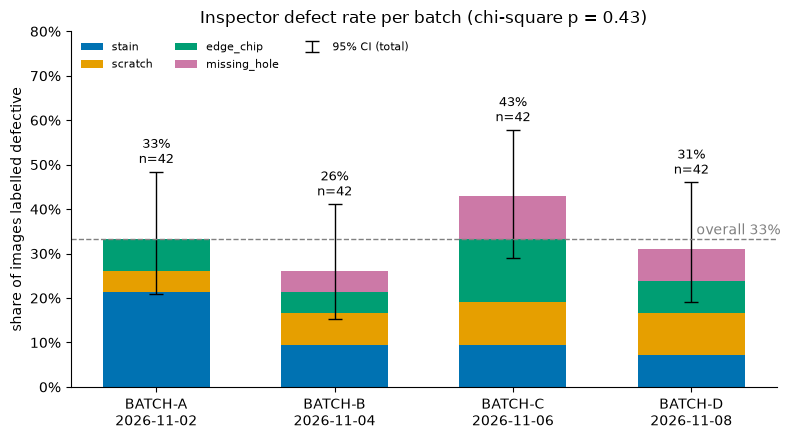

inspector_type,edge_chip,missing_hole,none,scratch,stain
batch,,,,,
BATCH-A,3,0,28,2,9
BATCH-B,2,2,31,3,4
BATCH-C,6,4,24,4,4
BATCH-D,3,3,29,4,3


In [7]:
batch = rate_table(train, "batch")
batch["date"] = train.groupby("batch")["timestamp_utc"].first().str[:10]
types = ["stain", "scratch", "edge_chip", "missing_hole"]
type_rate = (pd.crosstab(train["batch"], train["inspector_type"])[types]
             .div(batch["n_images"], axis=0))
overall = train["inspector_label"].mean()
chi2, p_batch, _, _ = stats.chi2_contingency(pd.crosstab(train["batch"], train["inspector_label"]))

colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, colour-blind safe
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(batch))
bottom = np.zeros(len(batch))
for t, c in zip(types, colors):
    ax.bar(x, type_rate[t], bottom=bottom, color=c, width=0.6, label=t)
    bottom += type_rate[t].to_numpy()
ax.errorbar(x, batch["defect_rate"],
            yerr=[batch["defect_rate"] - batch["ci_low"], batch["ci_high"] - batch["defect_rate"]],
            fmt="none", ecolor="black", capsize=5, lw=1, label="95% CI (total)")
ax.axhline(overall, ls="--", color="grey", lw=1)
ax.text(len(batch) - 0.5, overall + 0.01, f"overall {overall:.0%}", ha="right", color="grey")
for xi, (_, r) in zip(x, batch.iterrows()):
    ax.text(xi, r["ci_high"] + 0.02, f"{r['defect_rate']:.0%}\nn={r['n_images']}", ha="center", fontsize=9)
ax.set_xticks(x, [f"{b}\n{d}" for b, d in zip(batch.index, batch["date"])])
ax.set_ylabel("share of images labelled defective")
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f"Inspector defect rate per batch (chi-square p = {p_batch:.2f})")
ax.legend(ncol=3, fontsize=8, loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

pd.crosstab(train["batch"], train["inspector_type"])

**Insight.** The inspector's defect rate does **not** rise steadily (33 → 26 → 43 → 31%, chi-square p = 0.43). It peaks
on BATCH-C (6 Nov), and that peak is made of **geometric** defects (edge chips and missing holes), not stains. A
production problem would look like this; a lighting problem would not. A second pattern: `stain` labels cluster on
the first day (9 of 42 in BATCH-A, 3–4 on each later day). Stains are the most subjective defect type, so **before this
chart can answer the research question, the labels themselves must be checked**: Part B looks at those stain images,
and Part R corrects the labels and redraws this chart.

### A.4 (extra) Image-level distributions per acquisition setup, and outliers

The metadata shows no group effect on the labels. Are the **images themselves** different between
groups? Below: mean image brightness per camera/exposure setup, with outliers flagged by the 1.5×IQR
rule (computed over all training images).

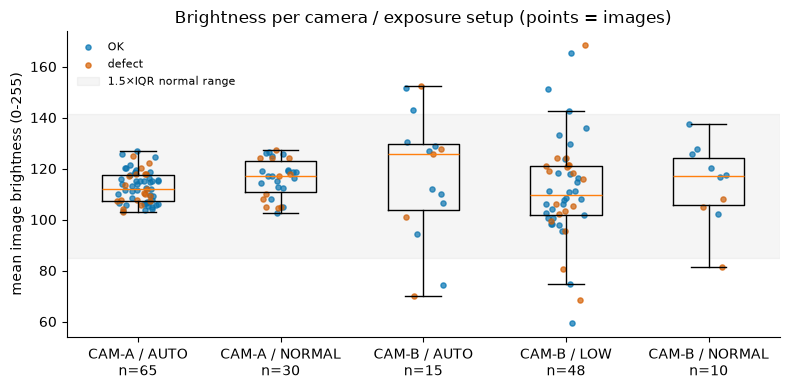

Kruskal-Wallis brightness across setups: p = 0.17
brightness outliers: 14 — by camera: {'CAM-B': 14}; defect rate 43% vs 33% overall


sharpness median: CAM-A 402 vs CAM-B 585 (Kruskal-Wallis p = 2.35e-07); AUC vs label = 0.46


,image_id,setup,batch,mean_brightness,inspector_type
55,IMG_0080,CAM-B / LOW,BATCH-B,59.4,none
121,IMG_0176,CAM-B / LOW,BATCH-C,68.4,edge_chip
89,IMG_0130,CAM-B / AUTO,BATCH-C,70.1,scratch
156,IMG_0224,CAM-B / AUTO,BATCH-D,74.2,none
128,IMG_0183,CAM-B / LOW,BATCH-D,74.7,none
107,IMG_0157,CAM-B / LOW,BATCH-C,80.5,stain
160,IMG_0229,CAM-B / NORMAL,BATCH-D,81.4,scratch
144,IMG_0209,CAM-B / LOW,BATCH-D,142.5,none
126,IMG_0181,CAM-B / AUTO,BATCH-D,143.1,none
165,IMG_0236,CAM-B / LOW,BATCH-D,151.3,none


In [8]:
train["mean_brightness"] = [np.asarray(Image.open(DATA_DIR / f).convert("L"), dtype=float).mean()
                            for f in train["file"]]
train["setup"] = train["camera"] + " / " + train["exposure_setting"]
q1, q3 = train["mean_brightness"].quantile([0.25, 0.75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
train["brightness_outlier"] = ~train["mean_brightness"].between(lo, hi)

setups = sorted(train["setup"].unique())
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([train.loc[train["setup"] == s, "mean_brightness"] for s in setups], showfliers=False)
rng = np.random.default_rng(SEED)
for i, s in enumerate(setups, start=1):
    sub = train[train["setup"] == s]
    for lab, color in [(0, "#0072B2"), (1, "#D55E00")]:
        v = sub[sub["inspector_label"] == lab]
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v["mean_brightness"], s=14, color=color, alpha=0.7,
                   label=("OK" if lab == 0 else "defect") if i == 1 else None)
ax.axhspan(lo, hi, color="grey", alpha=0.08, label="1.5×IQR normal range")
ax.set_xticks(range(1, len(setups) + 1), [f"{s}\nn={(train['setup'] == s).sum()}" for s in setups])
ax.set_ylabel("mean image brightness (0-255)")
ax.set_title("Brightness per camera / exposure setup (points = images)")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

p_setup = stats.kruskal(*[g["mean_brightness"] for _, g in train.groupby("setup")]).pvalue
print(f"Kruskal-Wallis brightness across setups: p = {p_setup:.2f}")
out = train[train["brightness_outlier"]]
print(f"brightness outliers: {len(out)} — by camera: {out['camera'].value_counts().to_dict()}; "
      f"defect rate {out['inspector_label'].mean():.0%} vs {train['inspector_label'].mean():.0%} overall")

# The brief warns that blur is not a defect either: sharpness = variance of the Laplacian (higher = sharper/noisier).

train["sharpness"] = [ndimage.laplace(np.asarray(Image.open(DATA_DIR / f).convert("L"), dtype=float)).var()
                      for f in train["file"]]
sharp_by_cam = [g["sharpness"] for _, g in train.groupby("camera")]
print(f"sharpness median: CAM-A {sharp_by_cam[0].median():.0f} vs CAM-B {sharp_by_cam[1].median():.0f} "
      f"(Kruskal-Wallis p = {stats.kruskal(*sharp_by_cam).pvalue:.3g}); "
      f"AUC vs label = {roc_auc_score(train['inspector_label'], train['sharpness']):.2f}")
out.sort_values("mean_brightness")[["image_id", "setup", "batch", "mean_brightness", "inspector_type"]].round(1)

**Insight.** The typical brightness is similar between setups, but **every brightness outlier comes from
CAM-B**. CAM-B produces both very dark and very bright frames, across all its exposure settings, while
CAM-A stays in range. So CAM-B's exposure control is unstable. The outliers are labelled defective
somewhat more often than average, but with ~14 images that is weak evidence. Several of the darkest
frames are labelled OK, so a dark image does not mean a defective part. **Implication for the
solution:** image features must use thresholds relative to each image, not fixed grey levels,
and camera/exposure must not be model inputs.

Sharpness tells the same story: CAM-B images are sharper or noisier (median 585 vs 402, p < 0.001), but sharpness
is unrelated to the label (AUC 0.46), so blur is not a defect signal here either.

## Part B — Understanding the images and extracting features

### B.1 Six sample images
Two OK plates (one from each camera/exposure setup) and one image of each defect type.

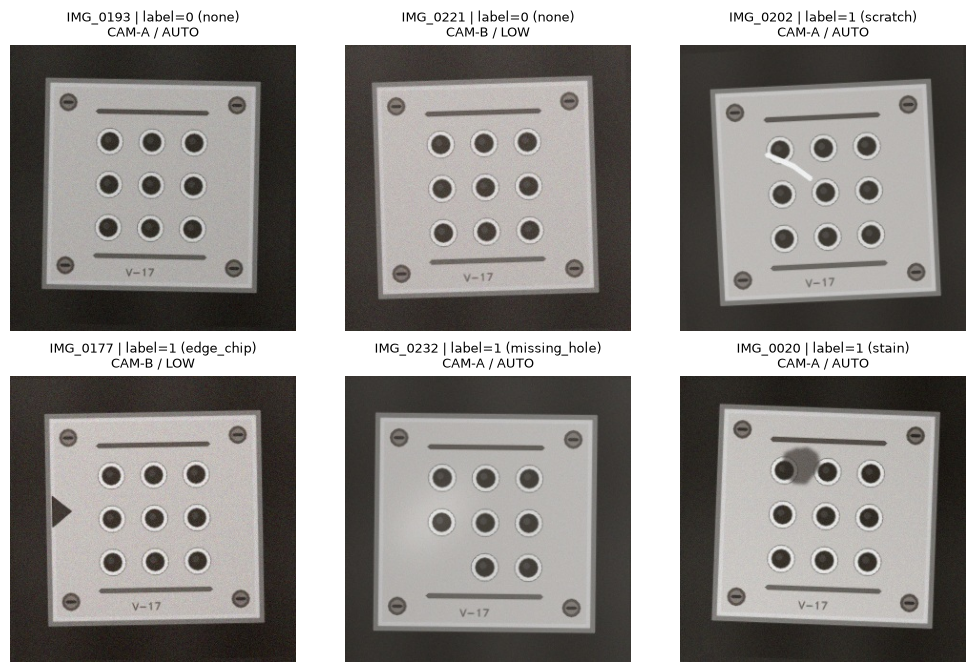

In [9]:
def show_grid(rows: pd.DataFrame, ncols: int = 3, size: float = 3.4) -> None:
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, (_, r) in zip(np.atleast_1d(axes).flat, rows.iterrows()):
        ax.imshow(Image.open(DATA_DIR / r["file"]))
        ax.set_title(f"{r['image_id']} | label={r['inspector_label']} ({r['inspector_type']})\n"
                     f"{r['camera']} / {r['exposure_setting']}", fontsize=9)
    plt.tight_layout()
    plt.show()

ok = train[train["inspector_label"] == 0]
samples = pd.concat([
    ok[(ok["camera"] == "CAM-A") & (ok["exposure_setting"] == "AUTO")].sample(1, random_state=SEED),
    ok[(ok["camera"] == "CAM-B") & (ok["exposure_setting"] == "LOW")].sample(1, random_state=SEED),
    *[train[train["inspector_type"] == t].sample(1, random_state=SEED)
      for t in ["scratch", "edge_chip", "missing_hole"]],
    train[train["image_id"] == "IMG_0020"],  # a stain that is clearly visible
])
show_grid(samples)

**Visual differences.** All plates share one design: a light face with a 3×3 grid of dark holes, four
screws, two bars and a "V-17" mark. Each defect type is a **local, geometric change** to that design:
a **missing hole** leaves a gap in the grid, an **edge chip** is a dark triangular notch cut into the edge of
the light face, a **scratch** is a thin line across the face, and a **stain** is a dark blotch. Overall
brightness, by contrast, changes mainly with camera and exposure: the CAM-B / LOW plate is darker
even though it is OK. This is why the features below measure the plate's **structure** and not its
global brightness.

**Label quality check.** The `stain` labels are concentrated in BATCH-A (Part A). Looking at all of them:

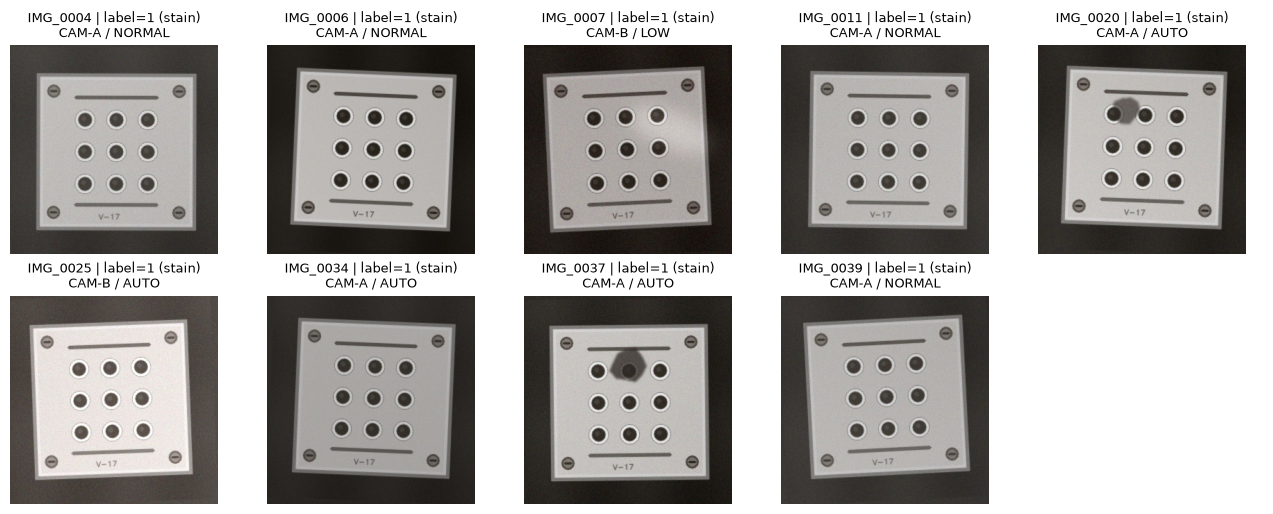

In [10]:
show_grid(train[(train["inspector_type"] == "stain") & (train["batch"] == "BATCH-A")], ncols=5, size=2.6)

Of the 9 BATCH-A images labelled `stain`, only **2 (IMG_0020, IMG_0037) show a visible blotch**. One
(IMG_0007) shows a bright reflection, which is a lighting artefact and not a stain, and the rest look like
clean plates. This is direct evidence that **part of the "defect" labels are inspector noise**, at least
for stains in BATCH-A. It caps how accurate any model can look on this data and is
relevant to the "rise in alerts" question. Part R audits all labels.

### B.2 Feature function

Two simple features, each aimed at a specific defect mechanism. Both use **thresholds computed
per image (Otsu)**, so they adapt to each image's exposure instead of using fixed grey levels.

1. **`n_round_marks`**: the number of round dark marks on the plate. An intact plate has
   **13** (9 holes + 4 screws). A missing hole lowers the count, and a scratch or stain crossing a hole
   merges or deforms it, which also lowers the count.
2. **`edge_notch_px`**: the depth in pixels of the deepest dent in the outline of the light face
   (the max convexity-defect depth). A straight-edged face gives ~1 px, and an edge chip cuts a notch
   of about 12–26 px.

In [11]:
def load_gray(path: Path) -> np.ndarray:
    """Read an image as grayscale; works with non-ASCII paths and fails loudly."""
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"cannot decode image: {path}")
    return img


def segment(path: Path) -> dict:
    """Shared preprocessing: plate mask, per-image dark/light threshold, dark-mark mask."""
    gray = load_gray(path)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # Plate = largest bright region against the dark background (global Otsu).
    _, bright = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(bright, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    plate = np.zeros_like(blur)
    cv2.drawContours(plate, [max(contours, key=cv2.contourArea)], -1, 255, thickness=-1)

    # Otsu on plate pixels only: splits dark marks (holes, screws, defects) from the light face.
    t, _ = cv2.threshold(blur[plate > 0].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    inner = cv2.erode(plate, np.ones((15, 15), np.uint8))  # excludes the plate border
    dark = ((blur < t) & (inner > 0)).astype(np.uint8) * 255
    marks, _ = cv2.findContours(dark, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return dict(gray=gray, blur=blur, plate=plate, t=t, dark=dark, marks=marks)


def circularity(c: np.ndarray) -> float:
    perim = cv2.arcLength(c, True)
    return 4 * np.pi * cv2.contourArea(c) / (perim ** 2) if perim > 0 else 0.0  # 1.0 = circle


def extract_features(path: Path) -> dict[str, float]:
    """Return the two structural features of one plate image."""
    s = segment(path)
    blur, plate, t = s["blur"], s["plate"], s["t"]

    # Feature 1: round dark marks inside the plate.
    n_round = sum(1 for c in s["marks"] if cv2.contourArea(c) >= 100 and circularity(c) > 0.75)

    # Feature 2: deepest notch in the outline of the light face.
    face = ((blur > t) & (plate > 0)).astype(np.uint8) * 255
    contours, _ = cv2.findContours(face, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    outline = max(contours, key=cv2.contourArea)
    defects = cv2.convexityDefects(outline, cv2.convexHull(outline, returnPoints=False))
    notch = 0.0 if defects is None else defects.reshape(-1, 4)[:, 3].max() / 256.0  # fixed-point -> px

    return {"n_round_marks": n_round, "edge_notch_px": round(float(notch), 2)}


extract_features(DATA_DIR / samples.iloc[0]["file"])

{'n_round_marks': 13, 'edge_notch_px': 1.12}

### B.3 Features for all training images, and OK vs. defect comparison

In [12]:
feat_train = pd.DataFrame([extract_features(DATA_DIR / f) for f in train["file"]], index=train.index)
# `mean_brightness` (from A.4) is kept only as a baseline for comparison; it is not one of the two features.
df = pd.concat([train, feat_train], axis=1)

# How well does each single feature rank defects above OK images? (AUC: 0.5 = no signal, 1 = perfect)
auc = {
    "n_round_marks (fewer = suspicious)": roc_auc_score(df["inspector_label"], -df["n_round_marks"]),
    "edge_notch_px (deeper = suspicious)": roc_auc_score(df["inspector_label"], df["edge_notch_px"]),
    "mean_brightness (baseline)": roc_auc_score(df["inspector_label"], df["mean_brightness"]),
}
pd.Series(auc, name="AUC").round(3)

n_round_marks (fewer = suspicious)     0.693
edge_notch_px (deeper = suspicious)    0.628
mean_brightness (baseline)             0.472
Name: AUC, dtype: float64

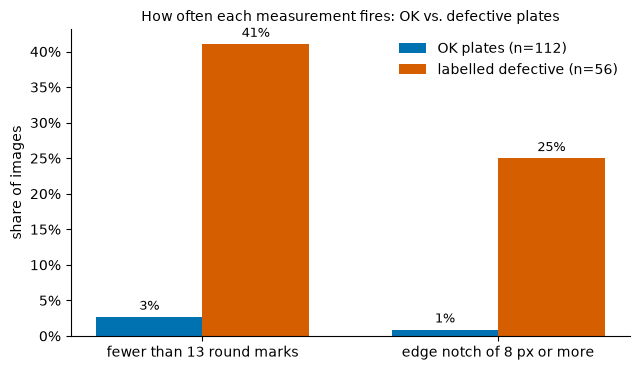

In [13]:
groups = {"OK plates": df["inspector_label"] == 0, "labelled defective": df["inspector_label"] == 1}
measures = {"fewer than 13 round marks": df["n_round_marks"] < 13,
            "edge notch of 8 px or more": df["edge_notch_px"] >= 8}

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x, w = np.arange(len(measures)), 0.36
for off, (name, mask), color in zip([-w / 2, w / 2], groups.items(), ["#0072B2", "#D55E00"]):
    vals = [m[mask].mean() for m in measures.values()]
    ax.bar(x + off, vals, w, color=color, label=f"{name} (n={mask.sum()})")
    for xi, v in zip(x + off, vals):
        ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, list(measures))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("share of images")
ax.set_title("How often each measurement fires: OK vs. defective plates", fontsize=10)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Comparison.** The two features cover **different defect types**, which is why they are paired:
- `edge_notch_px` separates edge chips from OK plates almost perfectly (chips ~12–26 px, OK ~1 px).
  It does not respond to the other defect types, by design.
- `n_round_marks` is exactly 13 for almost every OK plate and 12 for **every** missing-hole plate. It
  also drops below 13 for part of the scratches and stains (where the mark crosses a hole).
- Global brightness has **no** signal (AUC ≈ 0.5). Brightness tracks the camera and exposure, not the
  part, which matches the brief's warning that a dark image is not a defective part.
- The few **OK plates that trigger a measurement** (3 of 112 for the marks, 1 of 112 for the notch) are
  candidates for **missed defects by the inspector**. They are checked in Part R.

## Part C — A first, simple solution

### Design decisions
- **Inputs: image features only.** Camera, line, exposure and batch carry no significant label signal
  (Part A). Camera and exposure are tangled together, and the camera mix differs between train and
  test (CAM-A 57% vs 62%). A model using them would learn acquisition conditions, not part quality.
  `inspector_type` is never used (it encodes the label).
- **Two extra features**, added because Part B showed which defect types its two features miss:
  - `scratch_len_px`: the longest thin bright **or** dark line on the face, away from the plate's design
    elements (top-hat / black-hat filtering). The threshold is **relative to each image's own
    contrast between face and marks**, so CAM-B's unstable exposure (A.4) does not trigger it.
  - `stain_blob_px`: the area of the largest dark blob that is neither round (hole or screw) nor
    elongated (bar).
- **Decision rule, not a fitted model:** flag a plate if **any** of the four measurements fires: fewer than 13 round
  marks, an edge notch of 8 px or more, a thin line of 25 px or more, or a dark blob of 300 px² or more. Each
  threshold sits between the OK range and the defect range: an intact plate has exactly 13 round marks, OK notches are
  ~1 px against about 12–26 px for chips, and the printed "V-17" text gives OK plates up to ~22 px of "line".
  The **score** is the share of the four measurements that fire (0, 0.25, 0.5, ...). The brief asks for a suspicion
  score, not a calibrated probability. Every flag can be explained in one sentence ("the notch is 17 px deep").
- **Why not a learned model:** a logistic regression on the same four measurements makes exactly the same decisions
  (Part D), so it adds complexity without changing any flag. A deeper model would mostly memorise the label noise found
  in Part B.
- **Split:** 70% development / 30% validation, stratified by the inspector's defect type so that rare
  types appear in both. The rule has nothing to fit, so the development set is only used to sanity-check it. The
  validation set is used once, in Part D. `test.csv` is used only to produce predictions.
- **Honest caveat:** the feature parameters and the four thresholds were chosen by
  inspecting all 168 labelled images before the split. The validation scores are therefore somewhat
  optimistic. With a larger dataset, the parameters should be chosen on the development set only.

In [14]:
def thin_line_pieces(s: dict, mask_marks: bool = True) -> list[int]:
    """Lengths (px, longest first) of the thin bright/dark line pieces on the plate face.

    `mask_marks=True` is what the solution uses: the plate's own dark marks are excluded from the search.
    Part R calls this same function with False to measure the effect of that mask.
    """
    gray, blur, plate, t, dark = s["gray"], s["blur"], s["plate"], s["t"], s["dark"]
    # Thin bright/dark structures narrower than a 9 px disc.
    disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    g3 = cv2.GaussianBlur(gray, (3, 3), 0)
    thin = np.maximum(cv2.morphologyEx(g3, cv2.MORPH_TOPHAT, disc),
                      cv2.morphologyEx(g3, cv2.MORPH_BLACKHAT, disc))
    # Search only the face interior, away from the border (and, optionally, the plate's own marks).
    roi = cv2.erode(plate, np.ones((25, 25), np.uint8)) > 0
    if mask_marks:
        roi &= cv2.dilate(dark, np.ones((9, 9), np.uint8)) == 0
    face_contrast = np.median(blur[(blur > t) & (plate > 0)]) - t   # per-image scale
    lines = ((thin > 0.5 * face_contrast) & roi).astype(np.uint8)
    n, _, st, _ = cv2.connectedComponentsWithStats(lines, connectivity=8)
    return sorted((int(max(st[i, 2], st[i, 3])) for i in range(1, n) if st[i, 4] >= 10), reverse=True)


def extract_extra_features(path: Path) -> dict[str, float]:
    """Scratch and stain features (complement extract_features)."""
    s = segment(path)
    pieces = thin_line_pieces(s, mask_marks=True)
    scratch = pieces[0] if pieces else 0

    # Largest dark blob that is neither round (hole/screw) nor elongated (bar).
    stain = 0.0
    for c in s["marks"]:
        area = cv2.contourArea(c)
        (_, _), (w, h), _ = cv2.minAreaRect(c)
        if area >= 100 and circularity(c) <= 0.75 and max(w, h) / max(min(w, h), 1) < 3:
            stain = max(stain, area)
    return {"scratch_len_px": int(scratch), "stain_blob_px": float(stain)}


def feature_table(frame: pd.DataFrame) -> pd.DataFrame:
    rows = [{**extract_features(DATA_DIR / f), **extract_extra_features(DATA_DIR / f)} for f in frame["file"]]
    return pd.DataFrame(rows, index=frame.index)


FEATURES = ["missing_marks", "edge_notch_px", "scratch_len_px", "stain_blob_px"]

def model_inputs(feats: pd.DataFrame) -> pd.DataFrame:
    """Monotone 'more = more suspicious' inputs; log1p tames the long-tailed pixel features."""
    X = pd.DataFrame(index=feats.index)
    X["missing_marks"] = (13 - feats["n_round_marks"]).clip(lower=0)  # 13 = 9 holes + 4 screws
    for c in ["edge_notch_px", "scratch_len_px", "stain_blob_px"]:
        X[c] = np.log1p(feats[c])
    return X[FEATURES]

feats_tr = feature_table(train)
feats_te = feature_table(test)
data = pd.concat([train, feats_tr], axis=1)

order = ["none", "stain", "scratch", "missing_hole", "edge_chip"]

The four measurements were each designed for one defect type: the round-mark count for missing holes, the notch for edge
chips, the thin line for scratches and the dark blob for stains. How well they catch each type is measured on the
validation set in Part D (per-type recall). Stains are the weakest, which matches the unreliable stain labels found below.

In [15]:
RULES = {  # one fixed threshold per defect mechanism
    "fewer than 13 round marks": lambda f: f["n_round_marks"] < 13,
    "edge notch >= 8 px": lambda f: f["edge_notch_px"] >= 8,
    "thin line >= 25 px": lambda f: f["scratch_len_px"] >= 25,
    "dark blob >= 300 px²": lambda f: f["stain_blob_px"] >= 300,
}


def n_fired(feats: pd.DataFrame) -> pd.Series:
    """How many of the four measurements fire on each image."""
    return sum(rule(feats).astype(int) for rule in RULES.values())


def rule_predict(feats: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Decision = any measurement fires; score = share of the four measurements that fire."""
    k = n_fired(feats)
    return (k >= 1).astype(int), k / len(RULES)


dev_idx, val_idx = train_test_split(train.index, test_size=0.30, random_state=SEED,
                                    stratify=train["inspector_type"])
y_all = train["inspector_label"]
y_dev, y_val = y_all.loc[dev_idx], y_all.loc[val_idx]
print(f"dev: {len(dev_idx)} images ({y_dev.sum()} defect) | val: {len(val_idx)} images ({y_val.sum()} defect)")

# The rule has nothing to fit. On the development set: how often does each measurement fire on OK vs. defect plates?
f_dev = feats_tr.loc[dev_idx]
check = pd.DataFrame({name: {"OK plates": rule(f_dev)[y_dev == 0].mean(), "labelled defective": rule(f_dev)[y_dev == 1].mean()}
                      for name, rule in RULES.items()})
flag_dev, _ = rule_predict(f_dev)
check["any (the rule)"] = [flag_dev[y_dev == 0].mean(), flag_dev[y_dev == 1].mean()]
check.round(2)

dev: 117 images (39 defect) | val: 51 images (17 defect)


,fewer than 13 round marks,edge notch >= 8 px,thin line >= 25 px,dark blob >= 300 px²,any (the rule)
OK plates,0.04,0.01,0.01,0.00,0.06
labelled defective,0.44,0.26,0.13,0.23,0.79


On the development set the rule fires on 6% of OK plates and 79% of labelled defects. Each measurement on its own
fires on at most 4% of OK plates, and each catches a different part of the defects (round marks 44%, notch 26%, blob
23%, line 13%). That is why they are combined with OR: together they catch far more than any one of them, at almost no
cost in false alarms.

### Predictions for `test.csv`
The same fixed rule is applied to the test images, so the Part D validation numbers describe exactly the rule that
produced the predictions.

In [16]:
flag_te, score_te = rule_predict(feats_te)
pred = pd.DataFrame({
    "image_id": test["image_id"],
    "predicted_defect": flag_te.to_numpy(),
    "score": score_te.round(4).to_numpy(),
})

# Output contract checks.
assert len(pred) == 72 and pred["image_id"].tolist() == test["image_id"].tolist()
assert pred["predicted_defect"].isin([0, 1]).all() and pred["score"].between(0, 1).all()
pred.to_csv(DATA_DIR / "predictions.csv", index=False)

print(f"wrote predictions.csv: {len(pred)} rows, {pred['predicted_defect'].sum()} flagged as defect "
      f"({pred['predicted_defect'].mean():.0%}; train defect rate {train['inspector_label'].mean():.0%})")
pred.head()

wrote predictions.csv: 72 rows, 21 flagged as defect (29%; train defect rate 33%)

,image_id,predicted_defect,score
0,IMG_0001,1,0.25
1,IMG_0002,0,0.00
2,IMG_0003,0,0.00
3,IMG_0010,0,0.00
4,IMG_0014,1,0.50


### Sanity check of the test predictions
Before trusting the 72 predictions: are the test images measured in the same range as the training images, and do the
flags follow the camera (which would suggest a lighting effect and not the part)?

In [17]:
cmp = pd.DataFrame({
    "train median": feats_tr.median(), "test median": feats_te.median(),
    "train 5th-95th pct": [f"{a:.0f} to {b:.0f}" for a, b in zip(feats_tr.quantile(0.05), feats_tr.quantile(0.95))],
    "test 5th-95th pct": [f"{a:.0f} to {b:.0f}" for a, b in zip(feats_te.quantile(0.05), feats_te.quantile(0.95))],
})
display(cmp.round(1))
by_cam = pred.assign(camera=test["camera"]).groupby("camera")["predicted_defect"].agg(["size", "mean"]).round(2)
by_cam.columns = ["test images", "share flagged"]
p_cam_flag = stats.fisher_exact(pd.crosstab(test["camera"], pred["predicted_defect"]))[1]
print(f"flagged share by camera, Fisher p = {p_cam_flag:.2f}")
by_cam

,train median,test median,train 5th-95th pct,test 5th-95th pct
n_round_marks,13.0,13.0,12 to 13,12 to 13
edge_notch_px,1.1,1.1,1 to 17,1 to 19
scratch_len_px,7.5,7.0,5 to 25,2 to 21
stain_blob_px,0.0,0.0,0 to 303,0 to 256


flagged share by camera, Fisher p = 0.79


,test images,share flagged
camera,,
CAM-A,45,0.31
CAM-B,27,0.26


The test images are measured in the same range as the training images (identical medians; the 5th–95th percentile
ranges overlap closely), and the share flagged does not depend on the camera (31% vs 26%, p = 0.79), so there is no
sign that lighting drives the flags. The overall flag rate (29%) is close to the training defect rate (33%).

## Part D — Checking the results (validation set only)

### D.1 Confusion matrix, precision and recall

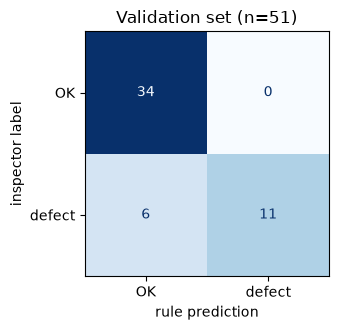

,precision,precision 95% CI,recall,recall 95% CI,accuracy
decision rule,1.00 (11/11),"[0.74, 1.00]",0.65 (11/17),"[0.41, 0.83]",0.88
baseline: always OK,undefined (no flags),,0.00,,0.67
baseline: flag everything,0.33,,1.00,,0.33


In [18]:
pred_val, score_val = rule_predict(feats_tr.loc[val_idx])

fig, ax = plt.subplots(figsize=(3.8, 3.4))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val), display_labels=["OK", "defect"]).plot(
    ax=ax, colorbar=False, cmap="Blues")
ax.set_xlabel("rule prediction"); ax.set_ylabel("inspector label")
ax.set_title(f"Validation set (n={len(y_val)})")
plt.tight_layout(); plt.show()

yv, pv = y_val.to_numpy(), pred_val.to_numpy()
tp, fp, fn = int(((pv == 1) & (yv == 1)).sum()), int(((pv == 1) & (yv == 0)).sum()), int(((pv == 0) & (yv == 1)).sum())

def wilson(k: int, n: int) -> str:
    """95% Wilson interval: with ~17 defects, one image moves recall by ~6 points."""
    ci = stats.binomtest(k, n).proportion_ci(method="wilson")
    return f"[{ci.low:.2f}, {ci.high:.2f}]"

res = pd.DataFrame({
    "precision": [f"{precision_score(yv, pv):.2f} ({tp}/{tp + fp})", "undefined (no flags)", f"{yv.mean():.2f}"],
    "precision 95% CI": [wilson(tp, tp + fp), "", ""],
    "recall": [f"{recall_score(yv, pv):.2f} ({tp}/{tp + fn})", "0.00", "1.00"],
    "recall 95% CI": [wilson(tp, tp + fn), "", ""],
    "accuracy": [f"{(yv == pv).mean():.2f}", f"{(yv == 0).mean():.2f}", f"{yv.mean():.2f}"],
}, index=["decision rule", "baseline: always OK", "baseline: flag everything"])
res

**Reading the numbers.** Every validation image the rule flagged was labelled defective (no false
alarms). It recovers about two thirds of the inspector's defects. Accuracy beats the "always OK" baseline
(0.67), but the intervals are wide: with 17 defects, recall could plausibly be anywhere from about 0.4 to 0.85.
The thresholds were not tuned for a cost. Since a missed defect usually costs more than a false alarm, looser
thresholds would trade precision for recall. That choice should be made on development data, with the
real costs, and not on this validation set. Part R.5 shows that 4 of the 6 misses are clean plates with a wrong
`stain` label, so the true recall is higher than it looks here.

### Recall per defect type, and the misses
`inspector_type` is used here **only to describe** the errors, never as a model input.

In [19]:
v = train.loc[val_idx, ["image_id", "camera", "exposure_setting", "inspector_label", "inspector_type"]].copy()
v["score"] = score_val.round(3)
v["pred"] = pred_val
v = v.join(feats_tr.loc[val_idx])
per_type = v.groupby("inspector_type").agg(n=("pred", "size"), flagged=("pred", "sum"))
per_type["flag_rate"] = (per_type["flagged"] / per_type["n"]).round(2)  # = recall for defect types, FP rate for 'none'
display(per_type.reindex(order))

errors = v[v["pred"] != v["inspector_label"]].sort_values("score", ascending=False)
errors[["image_id", "inspector_type", "score", "n_round_marks", "edge_notch_px", "scratch_len_px",
        "stain_blob_px", "camera", "exposure_setting"]]

,n,flagged,flag_rate
inspector_type,,,
none,34,0,0.00
stain,6,1,0.17
scratch,4,3,0.75
missing_hole,3,3,1.00
edge_chip,4,4,1.00


,image_id,inspector_type,score,n_round_marks,edge_notch_px,scratch_len_px,stain_blob_px,camera,exposure_setting
6,IMG_0011,stain,0.0,13,1.12,16,0.0,CAM-A,NORMAL
24,IMG_0034,stain,0.0,13,1.09,6,0.0,CAM-A,AUTO
113,IMG_0163,stain,0.0,13,1.13,20,0.0,CAM-A,NORMAL
78,IMG_0111,stain,0.0,13,1.16,6,0.0,CAM-B,LOW
51,IMG_0073,stain,0.0,13,1.00,15,0.0,CAM-A,AUTO
160,IMG_0229,scratch,0.0,13,1.11,15,0.0,CAM-B,NORMAL


### D.2 One error explained: IMG_0229 (validation, labelled `scratch`, no measurement fires, predicted OK)

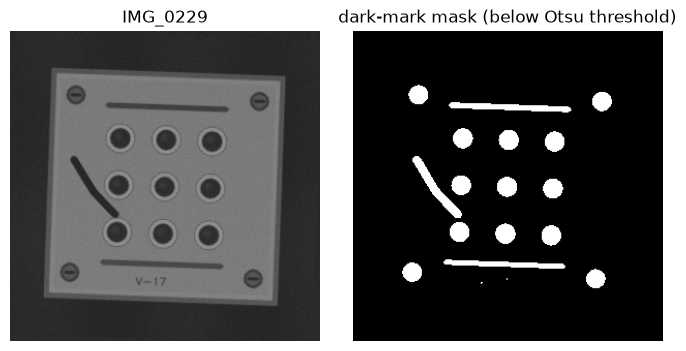

dark mark: area=530px², circularity=0.25, elongation=6.6
dark mark: area=528px², circularity=0.11, elongation=21.1
dark mark: area=460px², circularity=0.10, elongation=23.3


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
s229 = segment(DATA_DIR / "images/IMG_0229.jpg")
axes[0].imshow(s229["gray"], cmap="gray", vmin=0, vmax=255); axes[0].set_title("IMG_0229")
axes[1].imshow(s229["dark"], cmap="gray"); axes[1].set_title("dark-mark mask (below Otsu threshold)")
for a in axes:
    a.axis("off")
plt.tight_layout(); plt.show()

for c in sorted(s229["marks"], key=cv2.contourArea, reverse=True)[:3]:
    (_, _), (w, h), _ = cv2.minAreaRect(c)
    print(f"dark mark: area={cv2.contourArea(c):.0f}px², circularity={circularity(c):.2f}, "
          f"elongation={max(w, h) / max(min(w, h), 1):.1f}")

The plate has a clear, **thick dark scratch**, and it is a **dark CAM-B frame** (one of the brightness
outliers from A.4). The scratch is dark enough to fall below the image's own dark/light threshold, so it is treated
like the plate's printed marks:
- the scratch feature only searches *away* from dark marks, so it never sees this line;
- the stain feature ignores elongated marks (elongation ≥ 3), a rule meant to skip the two printed bars.
  The scratch has elongation ≈ 6.6, and the real bars are ≈ 21.

So the defect falls **between the features**. The obvious fix is an elongation band (about 3–15) or
excluding the bars by their position. **It is deliberately not applied here.** Changing a feature
after looking at validation errors would turn the validation set into a training set and inflate the reported
numbers. It is logged as the first next step instead.

### Does a learned model do better than the rule?
A logistic regression on the same four measurements (`class_weight="balanced"`, fit on the development set only, the
validation set untouched) is the natural next step up. If it found a better combination of the measurements, it
should be used instead.

In [21]:
X_all = model_inputs(feats_tr)
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_all.loc[dev_idx], y_dev)
THRESHOLD = 0.5  # with balanced class weights, 0.5 is the natural cut-off; not tuned
lr_val = pd.Series(model.predict_proba(X_all.loc[val_idx])[:, 1], index=val_idx)
lr_pred = (lr_val >= THRESHOLD).astype(int)
tn_l, fp_l, fn_l, tp_l = confusion_matrix(y_val, lr_pred).ravel()

print(f"decision rule:       TP={tp} FP={fp} FN={fn} | AUC = {roc_auc_score(y_val, score_val):.3f}")
print(f"logistic regression: TP={tp_l} FP={fp_l} FN={fn_l} | AUC = {roc_auc_score(y_val, lr_val):.3f}")
print("same validation images flagged:", bool((lr_pred == pred_val).all()))
pd.Series(model[-1].coef_[0], index=FEATURES, name="regression weight (per 1 std)").round(2)

decision rule:       TP=11 FP=0 FN=6 | AUC = 0.824
logistic regression: TP=11 FP=0 FN=6 | AUC = 0.861
same validation images flagged: True


missing_marks     1.43
edge_notch_px     0.99
scratch_len_px    0.82
stain_blob_px     0.52
Name: regression weight (per 1 std), dtype: float64

**No.** The regression flags **exactly the same validation images** as the rule (the same 11 caught, the same 6
missed). All four weights are positive and each measurement alone is enough to cross the
0.5 cut-off, so the regression has in effect learned "flag if anything fires". Its only advantage is a finer ranking
(a slightly higher AUC, not meaningful with 17 defects). **The value is in the measurements, not in the model**, so the
rule is kept because every flag can be explained. The regression is still useful as a diagnostic: its continuous
out-of-fold scores are used in Part R to look for hidden label errors.

## Part R (optional) — The evidence behind the answer
*Beyond the brief: Parts A–E stand on their own.*

Parts A–D treat the inspector's labels as the truth, but Part B showed that some are wrong. So the labels are checked
first (R.1–R.2), then the question is answered with the corrected labels (R.3–R.4), and finally the rule's own errors
are explained (R.5).

### R.1 Are the labels right?
**Bottom line: 15 of 168 labels (9%) are wrong.**

The rule from Part C is used as a second opinion that never sees the label. Every image where the rule and the label disagree (19 images)
was viewed at full resolution, first by the AI assistant and then by me; I agreed with all 19 decisions. Test images
were never reviewed.

| What the image shows | Decision |
|---|---|
| a clear defect, but the label says OK | **missed defect**: corrected to 1 |
| the label says defect, but the plate is clean (or shows only glare / over-exposure) | **false defect**: corrected to 0 |
| the label says defect, and a defect of another type is visible (IMG_0163) | label kept, type noted |
| the label is right and the rule is wrong (IMG_0160, 0215, 0229) | label kept, explained in R.5 |

The corrected labels are used only to study the labels and to re-score the rule; nothing is re-fitted with them.
Limit: an image where the rule and the inspector both missed a defect was never reviewed.

evidence,False,True
inspector_type,,
none,107,5
stain,12,8
scratch,2,11
missing_hole,0,9
edge_chip,0,14


label/evidence disagreements: 19 of 168 — all reviewed visually below


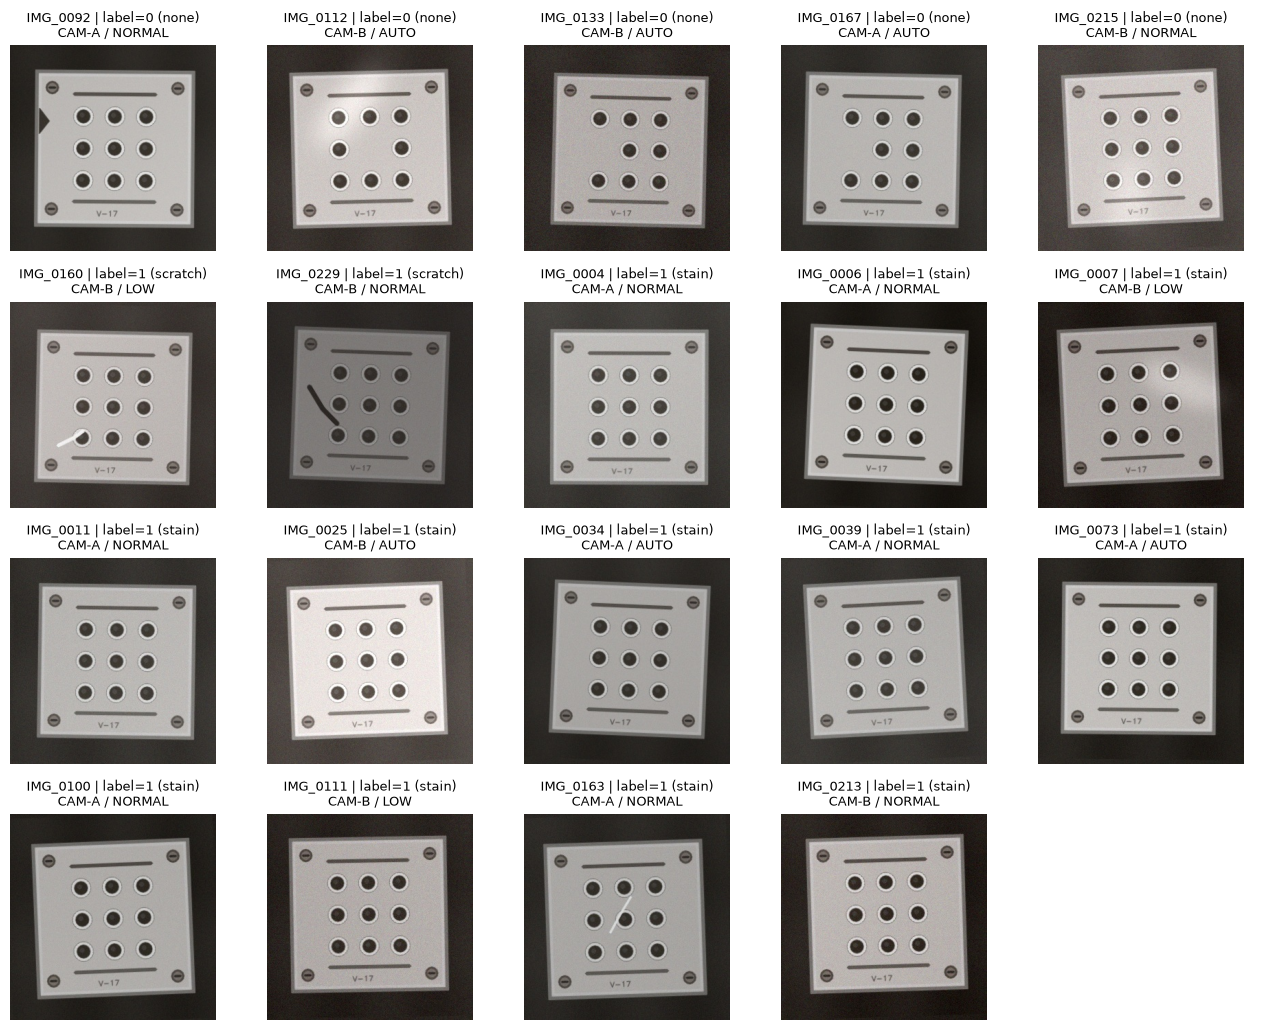

In [22]:
audit = train[["image_id", "file", "inspector_label", "inspector_type", "camera", "exposure_setting", "batch"]].join(feats_tr)
audit["evidence"] = n_fired(audit) >= 1  # the decision rule
display(pd.crosstab(audit["inspector_type"], audit["evidence"]).reindex(order))
disagree = audit[(audit["inspector_label"] == 1) != audit["evidence"]].sort_values(["inspector_label", "inspector_type"])
print(f"label/evidence disagreements: {len(disagree)} of {len(audit)} — all reviewed visually below")
show_grid(disagree, ncols=5, size=2.6)

**Verdicts for the 19 images.** The 8 `stain` labels that the rule agrees with were also checked: all 8 show a real stain.

In [23]:
VERDICT = {  # image_id: (true condition seen in the image, verdict on the inspector label)
    "IMG_0092": ("edge chip visible", "missed defect"),
    "IMG_0112": ("missing hole", "missed defect"),
    "IMG_0133": ("missing hole", "missed defect"),
    "IMG_0167": ("missing hole", "missed defect"),
    "IMG_0215": ("clean plate, strong glare", "label correct, detector false alarm"),
    "IMG_0160": ("scratch touching a hole", "label correct, detector miss"),
    "IMG_0229": ("thick dark scratch, dark frame", "label correct, detector miss"),
    "IMG_0163": ("scratch across a hole", "defect correct, wrong type (stain)"),
    "IMG_0007": ("clean plate, glare reflection", "false defect"),
    "IMG_0025": ("clean plate, over-exposed", "false defect"),
    **{i: ("clean plate", "false defect") for i in ["IMG_0004", "IMG_0006", "IMG_0011", "IMG_0034",
                                                     "IMG_0039", "IMG_0073", "IMG_0100", "IMG_0111", "IMG_0213"]},
}
assert set(VERDICT) == set(disagree["image_id"]), "every disagreement must have a verdict"
audit["seen"] = audit["image_id"].map(lambda i: VERDICT.get(i, ("", ""))[0])
audit["verdict"] = audit["image_id"].map(lambda i: VERDICT.get(i, ("", "agrees with evidence"))[1])
audit["verified_label"] = audit["inspector_label"]
audit.loc[audit["verdict"] == "false defect", "verified_label"] = 0
audit.loc[audit["verdict"] == "missed defect", "verified_label"] = 1

n_wrong = (audit["verified_label"] != audit["inspector_label"]).sum()
print(f"binary labels wrong: {n_wrong} of {len(audit)} ({n_wrong / len(audit):.0%}): "
      f"{(audit['verdict'] == 'false defect').sum()} false defects, {(audit['verdict'] == 'missed defect').sum()} missed defects")
st = audit[audit["inspector_type"] == "stain"]
n_real, n_other = (st["verdict"] == "agrees with evidence").sum(), st["verdict"].str.startswith("defect correct").sum()
print(f"stain labels: {n_real} real stains, {n_other} another defect type, {(st['verdict'] == 'false defect').sum()} with "
      f"no visible defect -> a defect is really there in {n_real + n_other} of {len(st)}")
audit.loc[audit["image_id"].isin(VERDICT), ["image_id", "inspector_type", "seen", "verdict", "batch", "camera",
                                             "exposure_setting"]].sort_values("verdict")

binary labels wrong: 15 of 168 (9%): 11 false defects, 4 missed defects
stain labels: 8 real stains, 1 another defect type, 11 with no visible defect -> a defect is really there in 9 of 20


,image_id,inspector_type,seen,verdict,batch,camera,exposure_setting
113,IMG_0163,stain,scratch across a hole,"defect correct, wrong type (stain)",BATCH-C,CAM-A,NORMAL
0,IMG_0004,stain,clean plate,false defect,BATCH-A,CAM-A,NORMAL
2,IMG_0006,stain,clean plate,false defect,BATCH-A,CAM-A,NORMAL
3,IMG_0007,stain,"clean plate, glare reflection",false defect,BATCH-A,CAM-B,LOW
6,IMG_0011,stain,clean plate,false defect,BATCH-A,CAM-A,NORMAL
18,IMG_0025,stain,"clean plate, over-exposed",false defect,BATCH-A,CAM-B,AUTO
24,IMG_0034,stain,clean plate,false defect,BATCH-A,CAM-A,AUTO
28,IMG_0039,stain,clean plate,false defect,BATCH-A,CAM-A,NORMAL
51,IMG_0073,stain,clean plate,false defect,BATCH-B,CAM-A,AUTO
70,IMG_0100,stain,clean plate,false defect,BATCH-B,CAM-A,NORMAL


#### Independent check: do the "false stains" look like clean plates in the image statistics?
The audit above relies on the rule and on a visual review, and the rule itself chose which images were reviewed. A
third check uses neither: nine whole-image statistics, compared as **full distributions** (Kolmogorov-Smirnov test),
not just averages. If the 11 false stains are really clean plates, they should be indistinguishable from OK plates,
while real defects should not be.

images per group: {'OK plate': 108, 'other real defect': 41, 'false stain': 11, 'real stain': 8}
KS p-value of each group vs. OK plates (below 0.05/9 = 0.0056 survives 9 comparisons):


,brightness,sharpness,plate contrast,face spread (std),face darkest 5%,skewness,entropy,dark-pixel share,light unevenness
false stain,0.449,0.760,0.937,0.723,0.893,0.986,0.871,0.612,0.729
real stain,0.925,0.214,0.023,0.128,0.844,0.000,0.192,0.000,0.678
other real defect,0.554,0.310,0.540,0.392,0.881,0.000,0.601,0.000,0.203


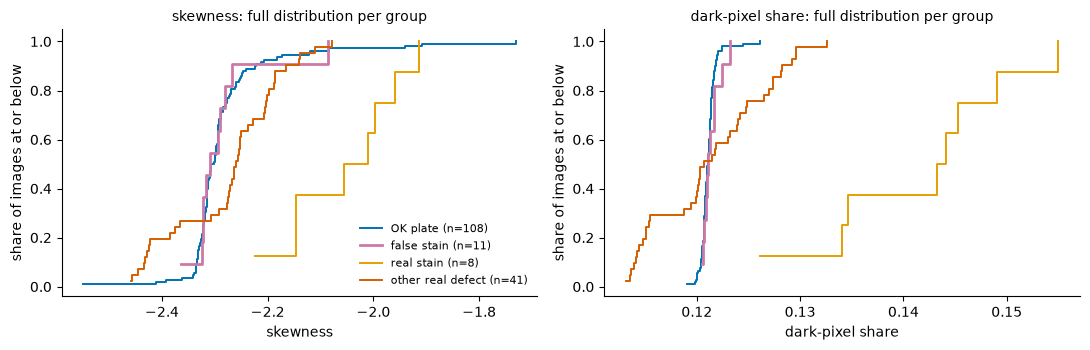

In [24]:
def image_stats(path: Path) -> dict[str, float]:
    """Nine whole-image statistics, none of them used by the rule."""
    s = segment(path)
    g, plate, t = s["gray"], s["plate"], s["t"]
    inner = cv2.erode(plate, np.ones((15, 15), np.uint8)) > 0
    v = g[inner].astype(float)
    face = v[v > t]
    hist = np.bincount(g[inner], minlength=256) / v.size
    hist = hist[hist > 0]
    return {
        "brightness": g.mean(),
        "sharpness": cv2.Laplacian(g, cv2.CV_64F).var(),
        "plate contrast": np.median(g[plate > 0]) - np.median(g[plate == 0]),
        "face spread (std)": face.std(),
        "face darkest 5%": np.percentile(face, 5),
        "skewness": stats.skew(v),
        "entropy": -(hist * np.log2(hist)).sum(),
        "dark-pixel share": (v < t).mean(),
        "light unevenness": np.abs(cv2.GaussianBlur(g, (0, 0), 25).astype(float)[inner] - np.median(v)).mean(),
    }


img = pd.DataFrame([image_stats(DATA_DIR / f) for f in audit["file"]], index=audit.index)
is_false = audit["verdict"] == "false defect"
group = pd.Series(np.select(
    [is_false, (audit["inspector_type"] == "stain") & (audit["verdict"] == "agrees with evidence"), audit["verified_label"] == 1],
    ["false stain", "real stain", "other real defect"], "OK plate"), index=audit.index)
ok = img[group == "OK plate"]

ks = pd.DataFrame({g: {c: stats.ks_2samp(img.loc[group == g, c], ok[c]).pvalue for c in img}
                   for g in ["false stain", "real stain", "other real defect"]}).T
print("images per group:", group.value_counts().to_dict())
print(f"KS p-value of each group vs. OK plates (below 0.05/9 = {0.05 / 9:.4f} survives 9 comparisons):")
display(ks.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col in zip(axes, ["skewness", "dark-pixel share"]):
    for g, color in [("OK plate", "#0072B2"), ("false stain", "#CC79A7"), ("real stain", "#E69F00"),
                     ("other real defect", "#D55E00")]:
        x = np.sort(img.loc[group == g, col])
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=color, lw=2 if g == "false stain" else 1.4,
                label=f"{g} (n={len(x)})")
    ax.set_xlabel(col)
    ax.set_ylabel("share of images at or below")
    ax.set_title(f"{col}: full distribution per group", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Bottom line: the 11 false stains are statistically indistinguishable from clean plates, and real defects are not.**
- **False stains vs. OK plates:** no difference on any of the nine statistics (every p ≥ 0.45). Their curves in the
  chart lie on top of the OK curve.
- **Real stains and other real defects vs. OK plates:** clearly different in skewness and dark-pixel share
  (p < 0.001, well below the 0.0056 bar for nine comparisons). A real defect adds dark pixels to the plate, and that
  shifts the whole brightness distribution.
- Brightness, sharpness and light unevenness separate no group from the OK plates, which again rules out the shooting
  conditions.

So a check that uses neither the rule nor the visual review agrees with both: the false stains are clean plates.

### R.2 Data: where do the wrong labels come from?
**Bottom line: all 11 false alarms are `stain` labels, and they are concentrated in the first days.**

In [25]:
audit["false_stain"] = audit["verdict"] == "false defect"
audit["timestamp_utc"] = train["timestamp_utc"]
audit["line"] = train["line"]
tests = {}
for g in ["batch", "camera", "exposure_setting", "line"]:  # `shift` excluded: unreliable (see data checks)
    ct = pd.crosstab(audit[g], audit["false_stain"])
    tests[g] = stats.fisher_exact(ct.values)[1] if ct.shape == (2, 2) else stats.chi2_contingency(ct)[1]
print("p-values (4 groupings tested; Bonferroni threshold 0.05/4 = 0.0125):",
      {k: round(float(v), 3) for k, v in tests.items()})


def perm_p(groups: np.ndarray, flag: np.ndarray, n_perm: int = 10_000) -> float:
    """Permutation p-value of the chi-square statistic. Unlike the asymptotic test it stays reliable with small counts."""
    codes = pd.factorize(groups)[0]
    k = codes.max() + 1
    total = np.bincount(codes, minlength=k)

    def stat(f: np.ndarray) -> float:
        pos = np.bincount(codes, weights=f, minlength=k)
        exp_pos, exp_neg = total * f.mean(), total * (1 - f.mean())
        return (((pos - exp_pos) ** 2) / exp_pos + (((total - pos) - exp_neg) ** 2) / exp_neg).sum()

    gen, f = np.random.default_rng(SEED), flag.astype(float)
    obs = stat(f)
    hits = sum(stat(gen.permutation(f)) >= obs - 1e-9 for _ in range(n_perm))
    return (hits + 1) / (n_perm + 1)


stain_only = audit[audit["inspector_type"] == "stain"]
print(f"batch, permutation p, all 168 images           = {perm_p(audit['batch'].to_numpy(), audit['false_stain'].to_numpy()):.4f}")
print(f"batch, permutation p, only the 20 stain labels = {perm_p(stain_only['batch'].to_numpy(), stain_only['false_stain'].to_numpy()):.4f}")
print("Bonferroni threshold: 0.0125 with 4 groupings, 0.0100 if `shift` were counted as a fifth.")

print("first stain labels in time order:")
audit[audit["inspector_type"] == "stain"].sort_values("timestamp_utc")[["image_id", "timestamp_utc", "seen"]].head(6)

p-values (4 groupings tested; Bonferroni threshold 0.05/4 = 0.0125): {'batch': 0.011, 'camera': 0.758, 'exposure_setting': 0.046, 'line': 0.06}


batch, permutation p, all 168 images           = 0.0099


batch, permutation p, only the 20 stain labels = 0.0525
Bonferroni threshold: 0.0125 with 4 groupings, 0.0100 if `shift` were counted as a fifth.
first stain labels in time order:


,image_id,timestamp_utc,seen
0,IMG_0004,2026-11-02T07:45:00Z,clean plate
2,IMG_0006,2026-11-02T08:15:00Z,clean plate
3,IMG_0007,2026-11-02T08:30:00Z,"clean plate, glare reflection"
6,IMG_0011,2026-11-02T09:30:00Z,clean plate
13,IMG_0020,2026-11-02T11:45:00Z,
18,IMG_0025,2026-11-02T13:00:00Z,"clean plate, over-exposed"


The first four stain labels in the data (2 Nov, 07:45–09:30) are all clean plates. On 2 and 4 Nov, 10 of 13 stain labels
show no defect, against 0 of 4 on 6 Nov. Day is the strongest grouping, but only borderline (p ≈ 0.01, right at the bar
for testing 4 groupings); camera, exposure and line are weaker (p ≥ 0.046). This points to the **labelling criterion**
(an unclear "stain" definition, or a new inspector), not to the camera. The 4 missed defects are all chips or missing
holes, on 4–6 Nov.

### R.3 Parts: with the corrected labels, what really rose, and when?
**Bottom line: real defects peak on 6 Nov, and the increase is chips and missing holes.**
Left: real defects per day by type, with the inspector's alert rate as black dots. Right: labelling errors per day.

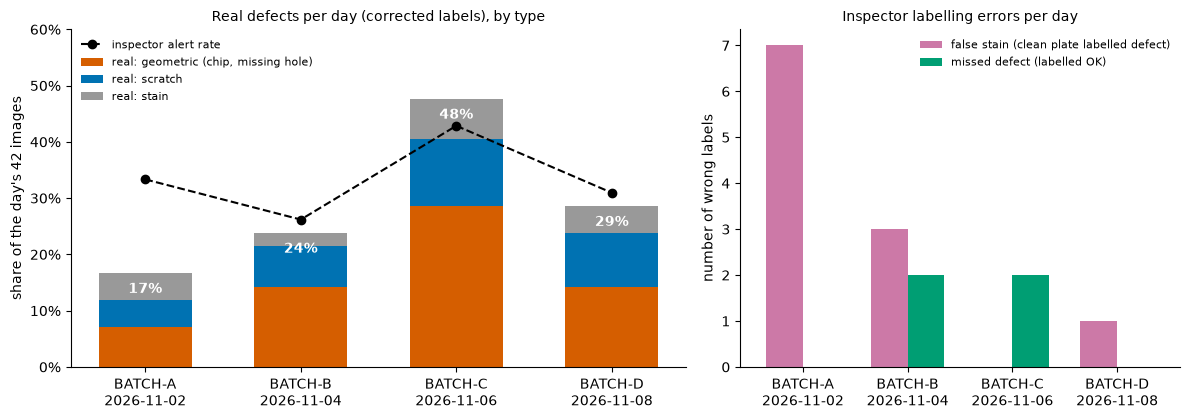

day 1 vs later days, inspector labels                odds ratio 1.00, Fisher p = 1.0000
day 1 vs later days, corrected labels                odds ratio 0.40, Fisher p = 0.0496
6 Nov vs other days, corrected labels                odds ratio 3.04, Fisher p = 0.0033
6 Nov vs other days, geometric defects only          odds ratio 2.96, Fisher p = 0.0155
all 4 days (chi-square): inspector labels p = 0.43 | corrected labels p = 0.014


,"geometric (chip, missing hole)",scratch,stain,false stain (clean plate labelled defect),missed defect (labelled OK)
BATCH-A\n2026-11-02,3,2,2,7,0
BATCH-B\n2026-11-04,6,3,1,3,2
BATCH-C\n2026-11-06,12,5,3,0,2
BATCH-D\n2026-11-08,6,4,2,1,0


In [26]:
SEEN_TYPE = {"edge chip visible": "edge_chip", "missing hole": "missing_hole"}
audit["verified_type"] = audit["inspector_type"]
audit.loc[audit["verdict"] == "false defect", "verified_type"] = "none"
missed = audit["verdict"] == "missed defect"
audit.loc[missed, "verified_type"] = audit.loc[missed, "seen"].map(SEEN_TYPE)
audit.loc[audit["image_id"] == "IMG_0163", "verified_type"] = "scratch"
assert ((audit["verified_type"] != "none") == (audit["verified_label"] == 1)).all()
GROUP = {"edge_chip": "geometric (chip, missing hole)", "missing_hole": "geometric (chip, missing hole)",
         "scratch": "scratch", "stain": "stain"}
audit["kind"] = audit["verified_type"].map(GROUP)
audit["line"] = train["line"]
audit["date"] = train["timestamp_utc"].str[:10]
batches = sorted(audit["batch"].unique())
labels = [f"{b}\n{audit.loc[audit['batch'] == b, 'date'].iloc[0]}" for b in batches]
n_day = audit.groupby("batch").size()

real = pd.crosstab(audit["batch"], audit["kind"]).reindex(batches).fillna(0)
real = real[["geometric (chip, missing hole)", "scratch", "stain"]]
errors = pd.DataFrame({"false stain (clean plate labelled defect)": audit.groupby("batch")["verdict"].apply(lambda v: (v == "false defect").sum()),
                       "missed defect (labelled OK)": audit.groupby("batch")["verdict"].apply(lambda v: (v == "missed defect").sum())}).reindex(batches)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
bottom = np.zeros(len(batches))
for col, color in zip(real.columns, ["#D55E00", "#0072B2", "#999999"]):
    share = real[col].to_numpy() / n_day.to_numpy()
    a1.bar(range(len(batches)), share, 0.6, bottom=bottom, color=color, label=f"real: {col}")
    bottom += share
for xi, tot in enumerate(bottom):
    a1.text(xi, tot - 0.035, f"{tot:.0%}", ha="center", color="white", fontweight="bold")
insp_rate = audit.groupby("batch")["inspector_label"].mean().reindex(batches)
a1.plot(range(len(batches)), insp_rate, "ko--", label="inspector alert rate")
a1.set_xticks(range(len(batches)), labels)
a1.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
a1.set_ylim(0, 0.6)
a1.set_ylabel("share of the day's 42 images")
a1.set_title("Real defects per day (corrected labels), by type", fontsize=10)
a1.legend(frameon=False, fontsize=8, loc="upper left")

errors.plot.bar(ax=a2, rot=0, color=["#CC79A7", "#009E73"], width=0.7)
a2.set_xticklabels(labels)
a2.set_xlabel("")
a2.set_ylabel("number of wrong labels")
a2.set_title("Inspector labelling errors per day", fontsize=10)
a2.legend(frameon=False, fontsize=8)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


def fisher_line(name: str, group: pd.Series, outcome: pd.Series) -> None:
    t = [[(group & outcome).sum(), (group & ~outcome).sum()], [(~group & outcome).sum(), (~group & ~outcome).sum()]]
    odds, p = stats.fisher_exact(t)
    print(f"{name:<52} odds ratio {odds:4.2f}, Fisher p = {p:.4f}")


day1, peak = audit["batch"] == batches[0], audit["batch"] == batches[2]
fisher_line("day 1 vs later days, inspector labels", day1, audit["inspector_label"] == 1)
fisher_line("day 1 vs later days, corrected labels", day1, audit["verified_label"] == 1)
fisher_line("6 Nov vs other days, corrected labels", peak, audit["verified_label"] == 1)
fisher_line("6 Nov vs other days, geometric defects only", peak, audit["kind"].str.startswith("geometric", na=False))
p_insp = stats.chi2_contingency(pd.crosstab(audit["batch"], audit["inspector_label"]))[1]
p_corr = stats.chi2_contingency(pd.crosstab(audit["batch"], audit["verified_label"]))[1]
print(f"all 4 days (chi-square): inspector labels p = {p_insp:.2f} | corrected labels p = {p_corr:.3f}")
display(pd.concat([real.astype(int), errors], axis=1).set_axis(labels, axis=0))

- **The rise is in the parts.** Real defects go from 17% on day 1 to 48% on 6 Nov, almost all of it chips and missing
  holes (3 → 12). Scratches rise only slightly (2 → 5), and real stains stay flat.
- **The labelling errors come early.** 7 false stains on day 1 push its rate from a real 17% to 33%. That flattens the
  inspector's curve and hides the rise.
- **How sure:** 6 Nov vs. the other days p = 0.003, but that day was picked after seeing the data, so it is a strong lead
  to check, not proof.

#### Why chips and missing holes point to production
They change the plate's shape. They are unambiguous to the eye, the rule finds them without looking at the label, and
they are not a lighting effect. A rise in these, unlike a rise in "stain" labels, is what a real production change
would leave. The cell below checks this.

In [27]:
audit["geometric"] = audit["kind"] == "geometric (chip, missing hole)"
orig_geo = audit["inspector_type"].isin(["edge_chip", "missing_hole"])
c_day = audit["batch"] == batches[2]
print(f"(1) BATCH-C holds {audit.loc[c_day, 'geometric'].sum()} of the {audit['geometric'].sum()} geometric defects "
      f"({audit.loc[c_day, 'geometric'].sum() / audit['geometric'].sum():.0%}) with {c_day.mean():.0%} of the images; "
      f"the other three days average {audit.loc[~c_day, 'geometric'].sum() / 3:.0f} per day.")
chips, holes = audit["inspector_type"] == "edge_chip", audit["inspector_type"] == "missing_hole"
print(f"(2) detector agrees with the inspector without seeing the label: notch >= 8 px on "
      f"{(audit.loc[chips, 'edge_notch_px'] >= 8).sum()}/{chips.sum()} chips, < 13 round marks on "
      f"{(audit.loc[holes, 'n_round_marks'] < 13).sum()}/{holes.sum()} missing holes; it also found the "
      f"{(audit['geometric'] & ~orig_geo).sum()} the inspector missed.")
for g in ["camera", "exposure_setting", "line"]:
    p = stats.chi2_contingency(pd.crosstab(audit[g], audit["geometric"]))[1]
    r = audit.groupby(g)["geometric"].mean().round(2).to_dict()
    print(f"(3) geometric share by {g}: {r}, chi-square p = {p:.2f}")
bc = audit[c_day & audit["geometric"]]
print(f"    inside BATCH-C the geometric defects are spread over both cameras {bc['camera'].value_counts().to_dict()} "
      f"and both lines {bc['line'].value_counts().to_dict()}")

(1) BATCH-C holds 12 of the 27 geometric defects (44%) with 25% of the images; the other three days average 5 per day.
(2) detector agrees with the inspector without seeing the label: notch >= 8 px on 14/14 chips, < 13 round marks on 9/9 missing holes; it also found the 4 the inspector missed.
(3) geometric share by camera: {'CAM-A': 0.14, 'CAM-B': 0.19}, chi-square p = 0.45
(3) geometric share by exposure_setting: {'AUTO': 0.16, 'LOW': 0.17, 'NORMAL': 0.15}, chi-square p = 0.98
(3) geometric share by line: {'LINE-1': 0.12, 'LINE-2': 0.2}, chi-square p = 0.27
    inside BATCH-C the geometric defects are spread over both cameras {'CAM-B': 6, 'CAM-A': 6} and both lines {'LINE-1': 6, 'LINE-2': 6}


The 12 geometric defects of 6 Nov are split evenly over both cameras and both lines, and the geometric share does not
depend on camera, exposure or line. So the excess is real and not a camera effect. The data cannot say *what* changed in
production: it has no machine, tool or operator column.

### R.4 Shooting conditions: do camera, exposure or machine explain the errors?
**Bottom line: no.** Wrong labels and wrong rule calls per group (`line` stands in for the machine, since there is no
machine ID):

In [28]:
audit["mean_brightness"] = train["mean_brightness"]
audit["brightness_outlier"] = train["brightness_outlier"]
audit["setup"] = audit["camera"] + " / " + audit["exposure_setting"]
audit["label_wrong"] = audit["verified_label"] != audit["inspector_label"]
audit["rule_wrong"] = audit["evidence"].astype(int) != audit["verified_label"]

rows = []
for g in ["camera", "exposure_setting", "line"]:
    t = audit.groupby(g).agg(images=("image_id", "size"), wrong_labels=("label_wrong", "sum"),
                             wrong_rule_calls=("rule_wrong", "sum"), brightness_outliers=("brightness_outlier", "sum"))
    t.index = pd.MultiIndex.from_product([[g], t.index])
    rows.append(t)
display(pd.concat(rows))
for g in ["camera", "exposure_setting", "line"]:
    print(f"{g:<17} permutation p: wrong labels {perm_p(audit[g].to_numpy(), audit['label_wrong'].to_numpy()):.3f} | "
          f"wrong rule calls {perm_p(audit[g].to_numpy(), audit['rule_wrong'].to_numpy()):.3f}")
print("rule calls that disagree with the verified label:")
audit.loc[audit["rule_wrong"], ["image_id", "camera", "exposure_setting", "inspector_label", "verified_label"]]

images  wrong_labels  wrong_rule_calls  \
camera           CAM-A       95             9                 1   
                 CAM-B       73             6                 3   
exposure_setting AUTO        80             6                 0   
                 LOW         48             2                 1   
                 NORMAL      40             7                 3   
line             LINE-1      88            12                 1   
                 LINE-2      80             3                 3   

                         brightness_outliers  
camera           CAM-A                     0  
                 CAM-B                    14  
exposure_setting AUTO                      5  
                 LOW                       8  
                 NORMAL                    1  
line             LINE-1                    8  
                 LINE-2                    6

camera            permutation p: wrong labels 0.792 | wrong rule calls 0.321


exposure_setting  permutation p: wrong labels 0.090 | wrong rule calls 0.024


line              permutation p: wrong labels 0.031 | wrong rule calls 0.345
rule calls that disagree with the verified label:


,image_id,camera,exposure_setting,inspector_label,verified_label
110,IMG_0160,CAM-B,LOW,1,1
113,IMG_0163,CAM-A,NORMAL,1,1
150,IMG_0215,CAM-B,NORMAL,0,0
160,IMG_0229,CAM-B,NORMAL,1,1


- **Camera:** wrong labels are 9 of 95 on CAM-A and 6 of 73 on CAM-B; no difference.
- **Machine (line):** 12 of the 15 wrong labels are on LINE-1, but they are mostly the early false stains, and the early
  stain labels were mostly LINE-1 too, so line and time cannot be separated.
- **Exposure:** 3 of the rule's 4 errors are on NORMAL exposure, but 4 cases cannot carry a conclusion.

#### Do glare and very dark or bright frames cause false alarms?

In [29]:
glare = ["IMG_0007", "IMG_0101", "IMG_0141"]  # visible reflections / uneven light
display(audit[audit["image_id"].isin(glare)][["image_id", "inspector_type", "n_round_marks", "edge_notch_px", "scratch_len_px", "stain_blob_px", "evidence"]])
o = audit[audit["brightness_outlier"]]
print(f"CAM-B brightness outliers (n={len(o)}): rule false-alarm rate on OK-labelled = "
      f"{o.loc[o['inspector_label'] == 0, 'evidence'].mean():.0%} "
      f"vs {audit.loc[audit['inspector_label'] == 0, 'evidence'].mean():.0%} on all OK-labelled")

,image_id,inspector_type,n_round_marks,edge_notch_px,scratch_len_px,stain_blob_px,evidence
3,IMG_0007,stain,13,1.89,8,0.0,False
71,IMG_0101,scratch,13,1.17,54,0.0,True
96,IMG_0141,missing_hole,12,1.00,9,0.0,True


CAM-B brightness outliers (n=14): rule false-alarm rate on OK-labelled = 0% vs 4% on all OK-labelled


No. The glare images are flagged only when they have a real defect (IMG_0101 a scratch, IMG_0141 a missing hole), and
the brightness outliers get no false alarms (0%). The risk is the opposite: a very dark frame can hide a dark defect
(IMG_0229, Part D.2).

### R.5 Error analysis: when the rule and the inspector disagree, who is wrong?
**Bottom line: mostly the inspector.** Every validation disagreement, compared with the verified label:

In [30]:
val_err = audit.loc[val_idx].assign(rule=np.asarray(pred_val))
val_err = val_err[val_err["rule"] != val_err["inspector_label"]]
val_err["error"] = np.where(val_err["rule"] == 0, "rule says OK, inspector says defect", "rule says defect, inspector says OK")
val_err["who is wrong"] = np.select(
    [val_err["verified_label"] == val_err["rule"], val_err["verified_label"] == val_err["inspector_label"]],
    ["inspector (label error)", "rule (detector error)"], "unclear")
display(val_err[["image_id", "error", "inspector_type", "seen", "verdict", "who is wrong"]].sort_values("who is wrong"))
print(val_err["who is wrong"].value_counts().to_string())

,image_id,error,inspector_type,seen,verdict,who is wrong
6,IMG_0011,"rule says OK, inspector says defect",stain,clean plate,false defect,inspector (label error)
24,IMG_0034,"rule says OK, inspector says defect",stain,clean plate,false defect,inspector (label error)
78,IMG_0111,"rule says OK, inspector says defect",stain,clean plate,false defect,inspector (label error)
51,IMG_0073,"rule says OK, inspector says defect",stain,clean plate,false defect,inspector (label error)
113,IMG_0163,"rule says OK, inspector says defect",stain,scratch across a hole,"defect correct, wrong type (stain)",rule (detector error)
160,IMG_0229,"rule says OK, inspector says defect",scratch,"thick dark scratch, dark frame","label correct, detector miss",rule (detector error)


who is wrong
inspector (label error)    4
rule (detector error)      2


**Why the rule goes wrong.** The two real rule errors above, plus the two found on the development images (IMG_0160,
IMG_0215), measured:

In [31]:
def line_pieces(path: Path, mask_marks: bool) -> list[int]:
    """Top-3 thin-line lengths, from the same helper the scratch feature uses."""
    return thin_line_pieces(segment(path), mask_marks)[:3]

for iid in ["IMG_0163", "IMG_0160"]:
    p = DATA_DIR / f"images/{iid}.jpg"
    print(f"{iid}: line pieces with mark mask {line_pieces(p, True)} | without mask {line_pieces(p, False)}")

IMG_0163: line pieces with mark mask [20, 18, 6] | without mask [122, 122, 80]
IMG_0160: line pieces with mark mask [24, 15, 7] | without mask [120, 120, 50]


| Image | Error | Measured cause |
|---|---|---|
| IMG_0163, IMG_0160 | scratch missed | the scratch crosses a hole, and masking the holes cuts it into pieces below 25 px (20+18 and 24+15 px; 80 and 50 px unmasked) |
| IMG_0229 | scratch missed | a dark scratch on a dark frame is taken for one of the plate's printed marks |
| IMG_0215 | false alarm | glare makes the printed "V-17" text read as a 30 px line |

All four have **one cause**: the line detector cannot tell a defect line from the plate's printed holes, bars and text.
The fix (compare with a clean reference plate) is not applied, because it was found by looking at the errors. These four
are the rule's only errors on all 168 labelled images.

#### Any hidden defects the rule cannot see?
The logistic regression from Part D gives a finer score than the rule, so the OK-labelled images with no rule evidence
are ranked by it (out-of-fold: each image scored by a model that did not see it):

In [32]:
# Out-of-fold: each image is scored by a regression that did not see it in training (5-fold CV).
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_all, train["inspector_type"]))
audit["oof_score"] = cross_val_predict(model, X_all, y_all, cv=folds, method="predict_proba")[:, 1].round(3)
quiet_ok = audit[(audit["inspector_label"] == 0) & ~audit["evidence"]].sort_values("oof_score", ascending=False)
print("highest-scoring OK-labelled images without detector evidence (all five reviewed: clean plates):")
print(", ".join(f"{r.image_id} ({r.oof_score:.2f})" for r in quiet_ok.head(5).itertuples()))

highest-scoring OK-labelled images without detector evidence (all five reviewed: clean plates):


IMG_0196 (0.47), IMG_0138 (0.45), IMG_0063 (0.44), IMG_0236 (0.44), IMG_0212 (0.43)


All five are clean plates; their scores come from the printed "V-17" text. No further hidden defects were found.

#### Re-scoring the rule against the corrected labels

In [33]:
def scores(y_true, y_pred) -> str:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(((y_pred == 1) & (y_true == 1)).sum()); fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return (f"precision {tp}/{tp + fp} = {tp / max(tp + fp, 1):.2f} {wilson(tp, tp + fp)}, "
            f"recall {tp}/{tp + fn} = {tp / max(tp + fn, 1):.2f} {wilson(tp, tp + fn)}")

vv = audit.loc[val_idx, "verified_label"]
print("VALIDATION vs inspector labels:", scores(y_val, pred_val))
print("VALIDATION vs verified labels: ", scores(vv, pred_val))
all_pred = audit["evidence"].astype(int)
print("ALL 168 vs inspector:", scores(audit["inspector_label"], all_pred))
print("ALL 168 vs verified: ", scores(audit["verified_label"], all_pred))

VALIDATION vs inspector labels: precision 11/11 = 1.00 [0.74, 1.00], recall 11/17 = 0.65 [0.41, 0.83]
VALIDATION vs verified labels:  precision 11/11 = 1.00 [0.74, 1.00], recall 11/13 = 0.85 [0.58, 0.96]
ALL 168 vs inspector: precision 42/47 = 0.89 [0.77, 0.95], recall 42/56 = 0.75 [0.62, 0.84]
ALL 168 vs verified:  precision 46/47 = 0.98 [0.89, 1.00], recall 46/49 = 0.94 [0.83, 0.98]


Against the corrected labels, validation recall rises from 0.65 to 0.85 and precision stays at 1.00. **This is an upper
bound, not a second estimate**: the rule itself chose which images were reviewed, so the honest numbers are those in D.1.

#### Summary: three sources of error

| Source | What | Fix |
|---|---|---|
| **Inspector labels** (4 of the 6 validation misses) | "stain" on clean plates, mostly early; missed chips and holes | a written stain definition with example images |
| **The rule** (2 of the 6) | scratches across holes, dark scratches on dark frames, printed text under glare | compare with a clean reference plate |
| **Shooting conditions** | very dark CAM-B frames can hide dark defects | stabilise camera B's exposure |

## Part E — Conclusions and use of AI

### Conclusions
1. **The rise in alerts is real and comes from the parts:** real defects went from 17% to 48% (6 Nov), almost all of it
   chips and missing holes. Next step: check what changed in production that day.
2. **The inspector's labels hide it:** 15 of 168 labels are wrong, mostly early "stain" labels on clean plates, which
   make the first day look as bad as the later ones.
3. **The shooting conditions are not the cause:** camera B's exposure is unstable, but it changes neither the defect
   rate nor the errors. Very dark frames can still hide dark defects, so it is worth fixing.
4. **A simple rule is a reasonable first screen:** precision 1.00 and recall 0.65 on validation (only 17 defects, so
   recall could be anywhere from 0.41 to 0.83). A logistic regression made the same decisions, so the readable rule
   is used.

### Limitations
- **Small data:** 4 days and 51 validation images. The time findings are leads, not proof.
- **Optimistic validation:** the thresholds were chosen while looking at all labelled images.
- **Audit blind spot:** only the 19 images where the rule and the inspector disagreed were reviewed, so defects both
  missed are not counted.
- **Data quality:** `shift` contradicts the timestamps, camera and exposure cannot be separated, and there is no
  machine ID.
- **In operation:** the rule assumes this one plate design; its thresholds should be set from the real cost of a miss
  versus a false alarm; and very dark frames should go to a person as "unreadable" instead of being scored.

### How I used AI, and how I checked it
Claude wrote most of the code and proposed features; I treated its output as a draft and tested it.
- I questioned the 100% validation precision, because it only measured agreement with labels I already knew were
  imperfect. That led to the label audit (Part R).
- I asked for checks by group and for outliers, which found camera B's unstable exposure; a second review caught the
  unreliable `shift` field.
- I rejected three AI feature versions that failed on the images: fixed brightness thresholds, a notch measured on the
  wrong outline, and a scratch threshold that fired on the whole plate.
- I replaced the AI's logistic regression with the simple rule once both made the same validation decisions.
- I reviewed all 19 audit images myself and agreed with every verdict.
- Leakage guards: the defect-type column is never a feature, `test.csv` is used only for the predictions, and a fix
  found on a validation error was deliberately not applied.